In [12]:
import numpy as np
import torch
import copy
import matplotlib.pyplot as plt
from envs.multi_agent_env import StagHuntEnv
from algorithms.r_pci import OutcomeBridgeNetwork, PolicyNetwork

def patch_env_for_cloning(env):
    """환경 인스턴스에 상태 저장/복원 기능을 동적으로 추가합니다."""
    def get_env_state():
        return copy.deepcopy(env.__dict__)
    
    def set_env_state(state):
        env.__dict__.update(copy.deepcopy(state))
        
    env.get_env_state = get_env_state
    env.set_env_state = set_env_state
    return env

env_config = {
    "num_agents": 3,
    "max_steps": 50,
    "stag_move_prob": 0.0,
    "coop_bonus": 0.0,
    "forage_reward": 3.0,
    "stag_reward": 5.0,
    "mauling_punishment": 0.0,
    "grid_observation": True,
    "obs_noise_std": 0.1
}

env = patch_env_for_cloning(StagHuntEnv(**env_config))
device = 'cpu' # 'cuda'

In [13]:
# 체크포인트 로드 (경로 설정 필요)
checkpoint_path = "save_checkpoints/20260315_202013/staghuntenv/checkpoints/final_checkpoint.pt"
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
algorithm_state = checkpoint['algorithm_state']

# ── 실제 checkpoint 키 구조 (trainer.py get_algorithm_state 기준) ──────────────────
#   algorithm_state
#     ├─ agents: {agent_id: {'policy_net': state_dict, 'optimizer': state_dict}}
#     ├─ outcome_bridge_net: state_dict
#     ├─ value_net: state_dict            (use_value_parameter_sharing=True 시)
#     └─ action_bridge_net, critic_kernel_z, critic_kernel_w, ...
# ─────────────────────────────────────────────────────────────────────────────────────

# 학습 시 사용한 설정값과 동일하게 맞춰야 합니다
obs_dim = env.get_obs_dim()   # 또는 직접 정수값으로: e.g. 27
alg_num_agents = 3
alg_action_dim = 5
alg_hidden_dim = 64
alg_recurrent_N = 1

from algorithms.r_pci import rPCIAlgorithm

policy = rPCIAlgorithm(
    env=env,
    num_agents=alg_num_agents,
    obs_dim=obs_dim,
    action_dim=alg_action_dim,
    w_dim=obs_dim * (alg_num_agents - 1),
    hidden_dim=alg_hidden_dim,
    recurrent_N=alg_recurrent_N,
    device=device,
)

# 각 에이전트의 policy_net 가중치 복원
for agent_id, agent_state in algorithm_state['agents'].items():
    policy.agents[agent_id].policy_net.load_state_dict(agent_state['policy_net'])
    policy.agents[agent_id].policy_net.eval()

# outcome_bridge_net 가중치 복원
outcome_bridge = policy.outcome_bridge_net
outcome_bridge.load_state_dict(algorithm_state['outcome_bridge_net'])
outcome_bridge.eval()

# value_net 복원 (있는 경우)
if 'value_net' in algorithm_state:
    policy.shared_value_net.load_state_dict(algorithm_state['value_net'])
elif 'value_nets' in algorithm_state:
    for agent_id, vn_state in algorithm_state['value_nets'].items():
        policy.value_nets[agent_id].load_state_dict(vn_state)

print(f"checkpoint load is completed (iteration={checkpoint.get('iteration', 'N/A')})")
print(f"   algorithm_type: {algorithm_state.get('algorithm_type', 'N/A')}")

class NaivePredictor:
    """교란(Confounding)을 무시하고 관측된 X_t^i와 A_t^i만으로 보상을 예측하는 가상의 비교군"""
    def __init__(self):
        # 실제로는 미리 학습된 신경망 모델이 들어갑니다.
        pass
        
    def predict(self, action, x_t_i):
        # 임시 반환값: 실제 모델의 forward pass 로직으로 대체하세요.
        return np.random.normal(loc=0.5, scale=0.1) 

naive_predictor = NaivePredictor()

checkpoint load is completed (iteration=1499)
   algorithm_type: rPCIAlgorithm


In [14]:
num_episodes = 50
K_mc = 30        # 각 (상태, 행동) 쌍마다 수행할 몬테카를로 롤아웃 횟수
num_agents = 3   # [cite: 475]
action_dim = 5   # 
hidden_dim = 64  # RNN 은닉층 차원 (설정에 맞게 변경)

mse_pci_list = []
mse_naive_list = []
true_effects_list = []
pci_preds_list = []
naive_preds_list = []

def obs_dict_to_tensor(obs_dict, device):
    """환경에서 반환된 obs dict를 torch tensor dict로 변환합니다."""
    return {
        i: torch.tensor(v, dtype=torch.float32, device=device)
        for i, v in obs_dict.items()
    }

def save_policy_rnn_states(policy):
    """policy 내부의 모든 에이전트 RNN hidden state를 저장합니다."""
    return {
        agent_id: (
            agent.rnn_state_policy.clone(),
            agent.prev_action.clone(),
        )
        for agent_id, agent in policy.agents.items()
    }

def restore_policy_rnn_states(policy, saved_states):
    """save_policy_rnn_states로 저장한 상태를 policy에 복원합니다."""
    for agent_id, (rnn_state, prev_action) in saved_states.items():
        policy.agents[agent_id].rnn_state_policy = rnn_state.clone()
        policy.agents[agent_id].prev_action = prev_action.clone()

def get_w_x(obs_dict, policy, agent_i, device):
    """
    r_pci.py의 update_causal_networks 로직(Option 1)과 동일하게 W^i_t, X^i_t를 구성합니다.

    W^i_t = O_t^{-i}  : agent_i를 제외한 다른 에이전트들의 관측값 concat
                         → r_pci.py: W_super = obs_others_super
                         shape: ((num_agents-1) * obs_dim,)

    X^i_t = (O_t^i, H_{t-1}^{-i}) : agent_i의 관측값 + 다른 에이전트들의 t-1 policy hidden state
                         → r_pci.py: X_super = cat(obs_super, H_others_super)  [Option 1]
                         shape: (obs_dim + (num_agents-1) * recurrent_N * hidden_dim,)
    """
    n = len(obs_dict)

    # W^i_t: 다른 에이전트들의 관측값 concat
    w_parts = [
        obs_dict[j] if isinstance(obs_dict[j], torch.Tensor)
        else torch.tensor(obs_dict[j], dtype=torch.float32, device=device)
        for j in range(n) if j != agent_i
    ]
    w_t_i = torch.cat(w_parts, dim=-1)  # ((num_agents-1)*obs_dim,)

    # X^i_t: agent_i 관측값
    obs_i = obs_dict[agent_i] if isinstance(obs_dict[agent_i], torch.Tensor) \
        else torch.tensor(obs_dict[agent_i], dtype=torch.float32, device=device)

    # 다른 에이전트들의 hidden state (t-1 기준): rnn_state_policy
    # shape per agent: (recurrent_N, hidden_dim) → flatten → (recurrent_N * hidden_dim,)
    h_others_parts = [
        policy.agents[j].rnn_state_policy.view(-1)
        for j in range(n) if j != agent_i
    ]
    h_others = torch.cat(h_others_parts, dim=-1)  # ((num_agents-1)*recurrent_N*hidden_dim,)

    x_t_i = torch.cat([obs_i, h_others], dim=-1)

    return w_t_i, x_t_i


device = policy.device

for ep in range(num_episodes):
    obs = env.reset()
    policy.reset_agents()

    done = False
    step = 0

    while not done and step < 50:  # 최대 50 스텝 [cite: 498]
        # 1. 원본 상태 완벽 보존 (환경 & RNN 메모리 모두!)
        saved_env_state = env.get_env_state()
        saved_rnn_states = save_policy_rnn_states(policy)

        obs_tensor = obs_dict_to_tensor(obs, device)

        for agent_i in range(num_agents):
            for a in range(action_dim):

                # --- [A] Ground Truth 인과 효과 (MC 롤아웃) ---
                mc_rewards = []
                for k in range(K_mc):
                    # 매 롤아웃마다 환경과 다른 에이전트들의 기억을 원상태로 리셋
                    env.set_env_state(saved_env_state)
                    restore_policy_rnn_states(policy, saved_rnn_states)

                    # 다른 에이전트들의 확률적 행동 샘플링
                    # rPCIAlgorithm.get_actions -> {agent_id: (action, log_prob)}
                    actions_dict = policy.get_actions(obs_tensor)
                    actions_env = {j: actions_dict[j][0] for j in range(num_agents)}
                    
                    # Intervention (개입): 에이전트 i의 행동을 강제로 a로 고정
                    actions_env[agent_i] = a

                    next_obs, rewards, dones, infos = env.step(actions_env)

                    team_reward = np.sum(list(rewards.values()) if isinstance(rewards, dict) else rewards)
                    mc_rewards.append(team_reward)

                mu_true = np.mean(mc_rewards)
                # --- [B] Estimator 예측값 (PCI) ---
                # r_pci.py update_causal_networks의 Option 1 로직과 동일하게 W, X 구성
                # saved_rnn_states(t-1 상태)를 복원하여 H_{t-1}^{-i} 성분이 올바른 값을 갖도록 보장
                restore_policy_rnn_states(policy, saved_rnn_states)

                # W^i_t = O_t^{-i}: 다른 에이전트들의 현재 관측값
                # X^i_t = (O_t^i, H_{t-1}^{-i}): 에이전트 i 관측 + 다른 에이전트들의 이전 hidden state
                w_t_i, x_t_i = get_w_x(obs_tensor, policy, agent_i, device)

                # outcome_bridge_net.forward(action, w, x) → (1, num_agents)
                action_tensor = torch.tensor([a], dtype=torch.long, device=device)  # (1,)
                w_tensor = w_t_i.unsqueeze(0)   # (1, w_dim)
                x_tensor = x_t_i.unsqueeze(0)   # (1, x_dim)

                with torch.no_grad():
                    r_hat_all = outcome_bridge.forward(action_tensor, w_tensor, x_tensor)  # (1, num_agents)
                # team reward 추정: 모든 에이전트 예측 보상의 합
                pci_est = r_hat_all[0].sum().item()

                # naive_est: NaivePredictor는 아직 미구현이므로 현재 상태 유지
                naive_est = naive_predictor.predict(a, x_t_i.cpu().numpy())

                # 데이터 기록
                mse_pci_list.append((mu_true - pci_est)**2)
                mse_naive_list.append((mu_true - naive_est)**2)

                true_effects_list.append(mu_true)
                pci_preds_list.append(pci_est)
                naive_preds_list.append(naive_est)

        # 2. 실제 에피소드 진행을 위해 상태 복구 후 1스텝 전진
        env.set_env_state(saved_env_state)
        restore_policy_rnn_states(policy, saved_rnn_states)
        actions_dict = policy.get_actions(obs_tensor)
        actions_env = {j: actions_dict[j][0] for j in range(num_agents)}
        obs, rewards, dones, infos = env.step(actions_env)

        # done 처리
        done = all(dones) if isinstance(dones, (list, np.ndarray)) else dones
        step += 1

print(f"Final PCI MSE: {np.mean(mse_pci_list):.4f}")
print(f"Final Naive MSE: {np.mean(mse_naive_list):.4f}")


Final PCI MSE: 0.4376
Final Naive MSE: 3.8441


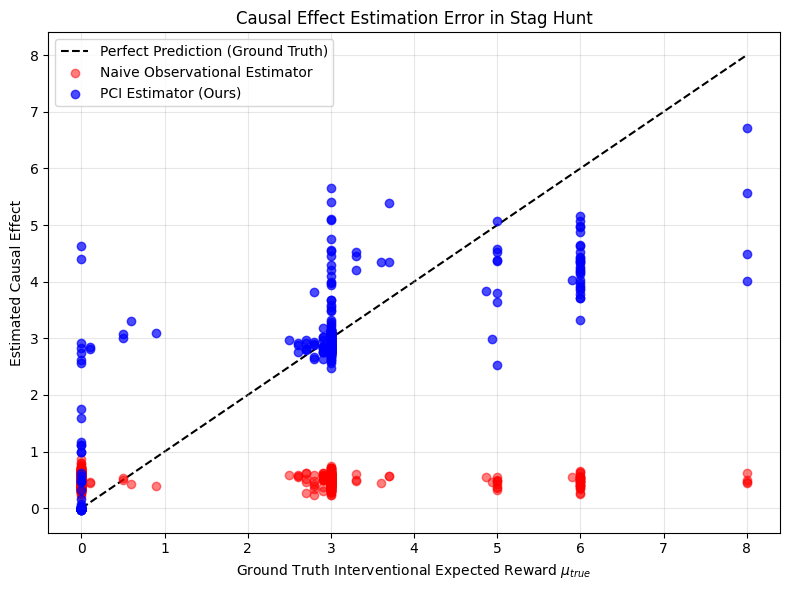

In [15]:
plt.figure(figsize=(8, 6))

# 기준선 y = x (완벽한 예측)
min_val = min(true_effects_list)
max_val = max(true_effects_list)
plt.plot([min_val, max_val], [min_val, max_val], 'k--', zorder=1, label="Perfect Prediction (Ground Truth)")

# 예측 결과 산점도
plt.scatter(true_effects_list, naive_preds_list, alpha=0.5, color='red', label='Naive Observational Estimator', zorder=2)
plt.scatter(true_effects_list, pci_preds_list, alpha=0.7, color='blue', label='PCI Estimator (Ours)', zorder=3)

plt.xlabel(r"Ground Truth Interventional Expected Reward $\mu_{true}$")
plt.ylabel("Estimated Causal Effect")
plt.title("Causal Effect Estimation Error in Stag Hunt")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# ── 헬퍼 함수: 체크포인트 로드 ──────────────────────────────────────────────
def load_policy_from_checkpoint(checkpoint_path, env, device,
                                 alg_num_agents=3, alg_action_dim=5,
                                 alg_hidden_dim=64, alg_recurrent_N=1):
    """
    체크포인트를 로드하여 rPCIAlgorithm 인스턴스(policy)를 반환합니다.
    """
    from algorithms.r_pci import rPCIAlgorithm
    obs_dim = env.get_obs_dim()

    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    algorithm_state = checkpoint['algorithm_state']

    policy = rPCIAlgorithm(
        env=env,
        num_agents=alg_num_agents,
        obs_dim=obs_dim,
        action_dim=alg_action_dim,
        w_dim=obs_dim * (alg_num_agents - 1),
        hidden_dim=alg_hidden_dim,
        recurrent_N=alg_recurrent_N,
        device=device,
    )

    for agent_id, agent_state in algorithm_state['agents'].items():
        policy.agents[agent_id].policy_net.load_state_dict(agent_state['policy_net'])
        policy.agents[agent_id].policy_net.eval()

    outcome_bridge = policy.outcome_bridge_net
    outcome_bridge.load_state_dict(algorithm_state['outcome_bridge_net'])
    outcome_bridge.eval()

    if 'value_net' in algorithm_state:
        policy.shared_value_net.load_state_dict(algorithm_state['value_net'])
    elif 'value_nets' in algorithm_state:
        for agent_id, vn_state in algorithm_state['value_nets'].items():
            policy.value_nets[agent_id].load_state_dict(vn_state)

    itr = checkpoint.get('iteration', 'N/A')
    print(f"  ✅ 로드 완료: {checkpoint_path}  (iteration={itr})")
    return policy, outcome_bridge


# ── 헬퍼 함수: 평가 실행 ────────────────────────────────────────────────────
def run_evaluation(policy, outcome_bridge, env, device,
                   num_episodes=100, K_mc=30, num_agents=3, action_dim=5):
    """
    주어진 policy와 outcome_bridge로 Monte-Carlo 기반 인과 효과 추정 평가를 실행합니다.
    반환값: (pci_mse, pci_preds, true_effects)
    """
    mse_pci_list = []
    true_effects_list = []
    pci_preds_list = []

    for ep in range(num_episodes):
        obs = env.reset()
        policy.reset_agents()
        done = False
        step = 0

        while not done and step < 50:
            saved_env_state = env.get_env_state()
            saved_rnn_states = save_policy_rnn_states(policy)
            obs_tensor = obs_dict_to_tensor(obs, device)

            for agent_i in range(num_agents):
                for a in range(action_dim):
                    # --- [A] Ground Truth (MC rollout) ---
                    mc_rewards = []
                    for k in range(K_mc):
                        env.set_env_state(saved_env_state)
                        restore_policy_rnn_states(policy, saved_rnn_states)

                        actions_dict = policy.get_actions(obs_tensor)
                        actions_env = {j: actions_dict[j][0] for j in range(num_agents)}
                        actions_env[agent_i] = a

                        next_obs, rewards, dones, infos = env.step(actions_env)
                        team_reward = np.sum(list(rewards.values()) if isinstance(rewards, dict) else rewards)
                        mc_rewards.append(team_reward)

                    mu_true = np.mean(mc_rewards)

                    # --- [B] PCI 추정값 ---
                    restore_policy_rnn_states(policy, saved_rnn_states)
                    w_t_i, x_t_i = get_w_x(obs_tensor, policy, agent_i, device)
                    action_tensor = torch.tensor([a], dtype=torch.long, device=device)
                    w_tensor = w_t_i.unsqueeze(0)
                    x_tensor = x_t_i.unsqueeze(0)

                    with torch.no_grad():
                        r_hat_all = outcome_bridge.forward(action_tensor, w_tensor, x_tensor)
                    pci_est = r_hat_all[0].sum().item()

                    mse_pci_list.append((mu_true - pci_est)**2)
                    true_effects_list.append(mu_true)
                    pci_preds_list.append(pci_est)

            # 실제 에피소드 진행
            env.set_env_state(saved_env_state)
            restore_policy_rnn_states(policy, saved_rnn_states)
            actions_dict = policy.get_actions(obs_tensor)
            actions_env = {j: actions_dict[j][0] for j in range(num_agents)}
            obs, rewards, dones, infos = env.step(actions_env)
            done = all(dones) if isinstance(dones, (list, np.ndarray)) else dones
            step += 1

    return np.mean(mse_pci_list), pci_preds_list, true_effects_list

In [18]:
# ── 여러 시드(Seeds)의 체크포인트에서 평가 실행 ─────────────────────────────
# 여러 번의 학습 런(독립된 Seed) 타임스탬프 디렉토리 목록
seeds_dirs = [
    "20260315_211010",
    "20260315_202013",
    "20260315_164539",
    "20260315_164538",
    "20260315_141625",
]

base_dir = "save_checkpoints"

# 평가할 iteration (500, 1000, 1499)
target_iters = {
    500:  "checkpoint_500.pt",
    1000: "checkpoint_1000.pt",
    1499: "final_checkpoint.pt"
}

EVAL_EPISODES = 100   # 에피소드 수
EVAL_K_MC = 30        # MC 롤아웃 횟수

# results 구조: { iteration: {'mse': [seed1_mse, seed2_mse, ...], 'preds': [...], 'truths': [...]} }
results = {itr: {'mse': [], 'preds': [], 'truths': []} for itr in target_iters.keys()}

print(f"총 {len(seeds_dirs)}개의 Seed(학습 런)에 대해 평가를 시작합니다...\n")

for seed_idx, s_dir in enumerate(seeds_dirs):
    print(f"=== Seed {seed_idx+1}/{len(seeds_dirs)}: [{s_dir}] ===")
    
    for itr, filename in target_iters.items():
        ckpt_path = f"{base_dir}/{s_dir}/staghuntenv/checkpoints/{filename}"
        
        try:
            pol, ob = load_policy_from_checkpoint(ckpt_path, env, device)
            mse, preds, truths = run_evaluation(
                pol, ob, env, device,
                num_episodes=EVAL_EPISODES,
                K_mc=EVAL_K_MC,
            )
            results[itr]['mse'].append(mse)
            results[itr]['preds'].extend(preds)
            results[itr]['truths'].extend(truths)
            print(f"  → Iter {itr:4d} | PCI MSE: {mse:.4f}")
        except FileNotFoundError:
            print(f"  [X] Iter {itr:4d} | 파일 없음: {ckpt_path}")
    print()

print("✅ 모든 다중 시드 평가 완료!")



[Iteration 500] 평가 시작...
  ✅ 로드 완료: save_checkpoints/20260315_202013/staghuntenv/checkpoints/checkpoint_500.pt  (iteration=500)
  → PCI MSE: 0.2462

[Iteration 1000] 평가 시작...
  ✅ 로드 완료: save_checkpoints/20260315_202013/staghuntenv/checkpoints/checkpoint_1000.pt  (iteration=1000)
  → PCI MSE: 0.2140

[Iteration 1499] 평가 시작...
  ✅ 로드 완료: save_checkpoints/20260315_202013/staghuntenv/checkpoints/final_checkpoint.pt  (iteration=1499)
  → PCI MSE: 0.1900

✅ 모든 체크포인트 평가 완료!
  Iteration  500: PCI MSE = 0.2462
  Iteration 1000: PCI MSE = 0.2140
  Iteration 1499: PCI MSE = 0.1900


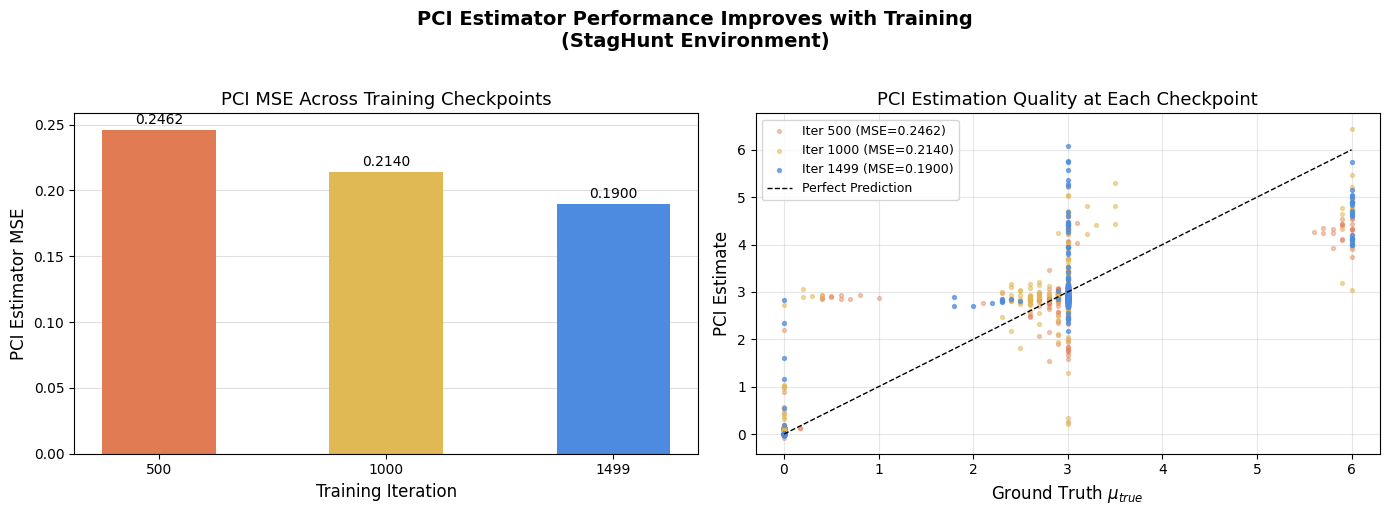

In [19]:
# ── Figure 1: Training 진행도별 PCI MSE (Learning Curve - Multi-Seed) ────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

iterations_sorted = sorted(results.keys())

# iteration별 평균 및 표준편차 계산
mean_mses = []
std_mses = []

for itr in iterations_sorted:
    mses_for_itr = results[itr]['mse']
    if mses_for_itr:
        mean_mses.append(np.mean(mses_for_itr))
        std_mses.append(np.std(mses_for_itr))
    else:
        mean_mses.append(0)
        std_mses.append(0)

mean_mses = np.array(mean_mses)
std_mses = np.array(std_mses)
x_labels = [str(i) for i in iterations_sorted]
x_positions = np.arange(len(iterations_sorted))

# (왼쪽) Line chart with Error Area: iteration별 MSE (다중 시드 평균/분산)
ax1 = axes[0]
color_line = '#4c8be0'

# 평균 선 그리기
ax1.plot(x_positions, mean_mses, marker='o', color=color_line, linewidth=2, markersize=8, label='Mean MSE', zorder=3)
# 표준편차 영역 칠하기 (Shaded Error Region)
ax1.fill_between(x_positions, mean_mses - std_mses, mean_mses + std_mses, color=color_line, alpha=0.2, label='±1 Std Dev', zorder=2)

ax1.set_xticks(x_positions)
ax1.set_xticklabels(x_labels)
ax1.set_xlabel("Training Iteration", fontsize=12)
ax1.set_ylabel("PCI Estimator MSE", fontsize=12)
ax1.set_title(f"PCI MSE learning curve across {len(seeds_dirs)} seeds", fontsize=13)
ax1.grid(True, linestyle='--', alpha=0.5, zorder=1)
ax1.legend(loc='upper right')

# (오른쪽) Scatter: Ground Truth vs. PCI pred (모든 시드 병합)
ax2 = axes[1]
scatter_colors = ['#e07b54', '#e0b854', '#4c8be0']
scatter_alphas = [0.2, 0.3, 0.4]

for idx, (itr, col, alpha) in enumerate(zip(iterations_sorted, scatter_colors, scatter_alphas)):
    truths = results[itr]['truths']
    preds = results[itr]['preds']
    if truths and preds:
        ax2.scatter(truths, preds, alpha=alpha, color=col, s=8,
                    label=f"Iter {itr}", zorder=2)

# 기준선 y=x
all_truths = []
for itr in iterations_sorted:
    all_truths.extend(results[itr]['truths'])
if all_truths:
    lim_min, lim_max = min(all_truths), max(all_truths)
    ax2.plot([lim_min, lim_max], [lim_min, lim_max], 'k--', linewidth=1,
             label="Perfect Prediction", zorder=3)

ax2.set_xlabel(r"Ground Truth $\mu_{true}$", fontsize=12)
ax2.set_ylabel("PCI Estimate", fontsize=12)
ax2.set_title("PCI Estimation Quality at Each Checkpoint (All Seeds)", fontsize=13)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

plt.suptitle("PCI Estimator Performance Overview (Multi-Seed)",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
